# 01 — Multi-View Dataset Scanning & Ground Truth IMU Processing

This notebook demonstrates the complete **Data Ingestion and Inertial Ground Truth (GT) Signal Processing Pipeline** used in **Gait360**.

### Pipeline Stages Covered:
1. **Multi-View Dataset Scanning & Stratified Cohort Breakdown**: Indexing synchronized RGB video streams, OpenPose 2D skeletons, and WitMotion IMU recordings across 8 viewing perspectives.
2. **IMU Data Loading & Dynamic Sampling Rate ($f_s$) Estimation**: Extracting timestamps, 3D linear accelerations (`accX, accY, accZ`), and Euler angles (`Roll, Pitch, Yaw`).
3. **Dataset-Wide Adaptive Welch PSD Profiling**: Automatically estimating the physiological gait passband $[f_{\text{low}}, f_{\text{high}}]$ from the median dominant stride harmonic ($f_{\text{median}}$).
4. **Zero-Phase 4th-Order Butterworth Bandpass Filtering**: Removing sensor drift and high-frequency vibro-impact noise via forward-backward filtering (`scipy.signal.filtfilt`) with zero phase distortion.
5. **3D Phase-Space Trajectory Visualization**: Inspecting centered raw vs filtered 3D acceleration and orientation orbits.
6. **Physiological Signal Quality Validation**: Enforcing biomechanical Range-of-Motion (ROM) and spectral purity constraints.

In [1]:
import os
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sp_signal

# Detect project root portably
current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "examples" else current_dir
os.chdir(str(project_root))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.rcParams["figure.dpi"] = 110
print(f"Workspace initialized: {project_root.name}")

Workspace initialized: monocular-3d-gait-tracking-deltav2


## 1. Multi-View Dataset Scanning & 40-Video Stratified Cohort

The `DatasetScanner` indexes the multi-view Gait Dataset (`data/cached_dataset_map.json`), linking each video clip with its frame-by-frame OpenPose 2D keypoints and corresponding inertial measurement unit (IMU) recording. From the validated trials with the IMU placed on the right thigh (`sensor_position == "leg"`), 40 balanced benchmark videos (40 unique subjects, 5 per viewing category) are selected.

Total indexed subjects in dataset map : 64
Total right-thigh IMU video trials    : 1344
Stratified benchmark cohort size      : 40 videos (40 unique subjects)


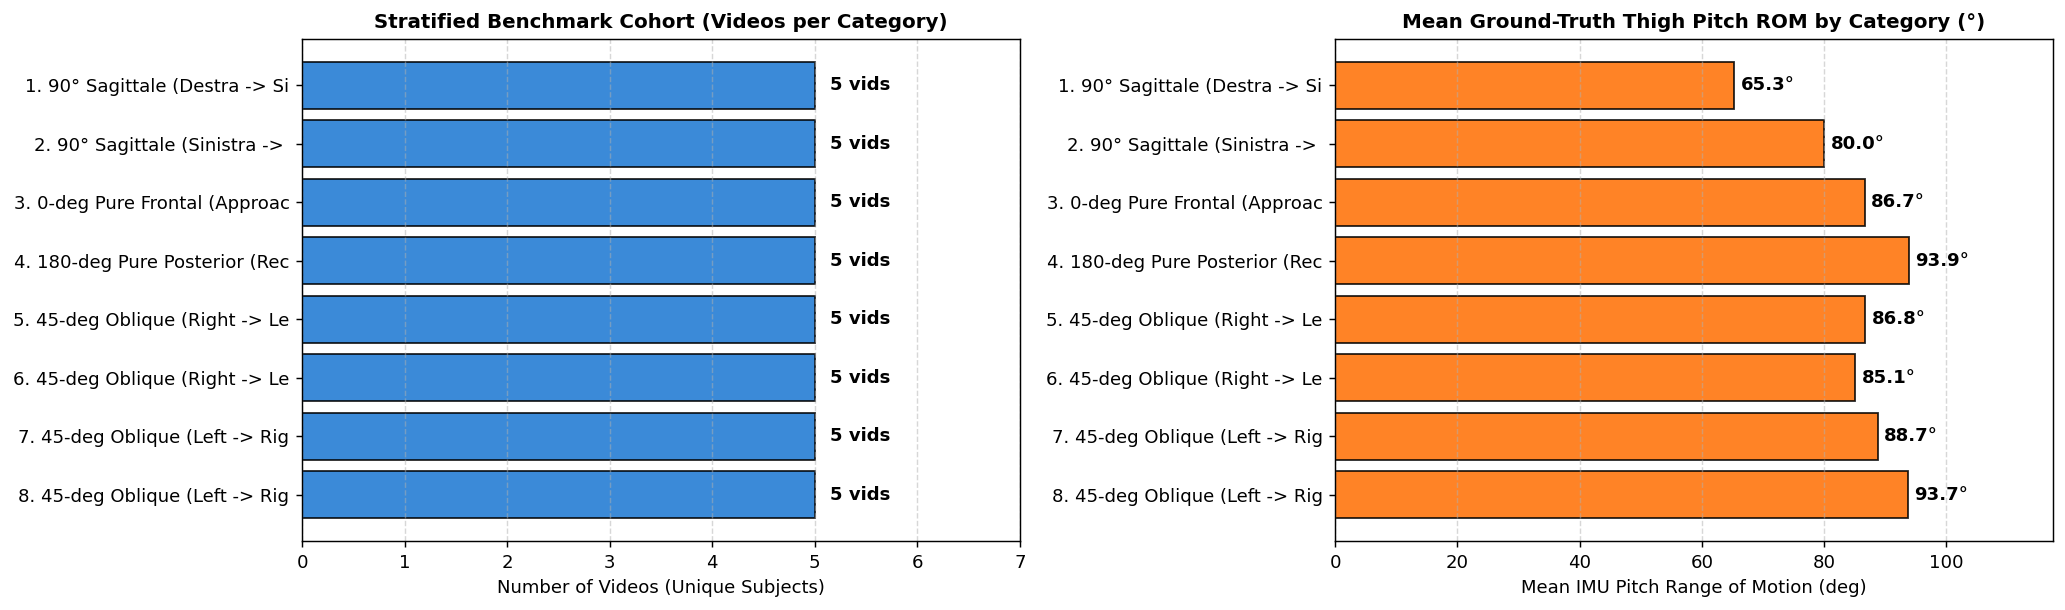

In [2]:
from src.data_io.dataset_scanner import DatasetScanner

scanner = DatasetScanner(str(project_root / "data"))
leg_trials = [v for v in scanner if v.sensor_data_path and v.sensor_position == "leg"]
df_cohort = pd.read_csv(project_root / "data" / "selected_inference_videos_40.csv")

print(f"Total indexed subjects in dataset map : {len(scanner.cached_dataset_map)}")
print(f"Total right-thigh IMU video trials    : {len(leg_trials)}")
print(f"Stratified benchmark cohort size      : {len(df_cohort)} videos ({df_cohort['person'].nunique()} unique subjects)")

# Plot cohort distribution and GT ROM by viewing category
cat_summary = df_cohort.groupby("category_8class").agg(
    count=("video_name", "count"),
    mean_rom=("gt_rom_deg", "mean"),
    mean_freq=("gt_step_freq_hz", "mean"),
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8))
short_labels = [c.split(".")[0] + "." + c.split(".")[1][:28] for c in cat_summary["category_8class"]]

bars1 = ax1.barh(short_labels, cat_summary["count"], color="#1976D2", edgecolor="black", alpha=0.85)
ax1.set_title("Stratified Benchmark Cohort (Videos per Category)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Number of Videos (Unique Subjects)")
ax1.set_xlim(0, 7)
ax1.invert_yaxis()
ax1.grid(axis="x", linestyle="--", alpha=0.5)
for b in bars1:
    ax1.text(b.get_width() + 0.15, b.get_y() + b.get_height()/2, f"{int(b.get_width())} vids", va="center", fontweight="bold")

bars2 = ax2.barh(short_labels, cat_summary["mean_rom"], color="#FF6D00", edgecolor="black", alpha=0.85)
ax2.set_title("Mean Ground-Truth Thigh Pitch ROM by Category (°)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Mean IMU Pitch Range of Motion (deg)")
ax2.set_xlim(0, max(cat_summary["mean_rom"]) * 1.25)
ax2.invert_yaxis()
ax2.grid(axis="x", linestyle="--", alpha=0.5)
for b in bars2:
    ax2.text(b.get_width() + 1.0, b.get_y() + b.get_height()/2, f"{b.get_width():.1f}°", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 2. IMU Sensor Data Loading & Dynamic Sampling Frequency ($f_s$)

We use `CsvSignalLoader` to parse the raw IMU recording for our reference trial (`P27_E2T2_90.mp4`). Because wireless Bluetooth IMU transmission can exhibit minor packet jitter, the effective sampling frequency $f_s$ is computed dynamically from the median inter-sample interval $\Delta t = \text{median}(t_{k+1} - t_k)$:
$$f_s = \frac{1}{\text{median}(\Delta t)}$$

In [3]:
from src.data_io.csv_loader import CsvSignalLoader
from src.preprocessing.signals.frequency_analysis import GaitFrequencyEstimator

video_info = next(v for v in leg_trials if v.name == "P27_E2T2_90.mp4")
loader = CsvSignalLoader()
estimator = GaitFrequencyEstimator(loader)

df_raw = loader.load(project_root / video_info.sensor_data_path)
fs = estimator._calculate_fs(df_raw["Timestamp"].values)

print(f"Selected Trial : {video_info.name} (Subject P{video_info.person}, Angle: {video_info.angle}°)")
print(f"Sensor CSV     : {Path(video_info.sensor_data_path).as_posix()}")
print(f"Samples Count  : {len(df_raw)} samples | Duration: {df_raw['Timestamp'].iloc[-1]:.2f} s | Calculated fs: {fs:.2f} Hz")
df_raw[["Timestamp", "accX", "accY", "accZ", "Roll", "Pitch", "Yaw"]].head(5)

Selected Trial : P27_E2T2_90.mp4 (Subject P27, Angle: 90°)
Sensor CSV     : data/Gait_Dataset/Participant_27/Experiment_2/E2T2/P27_E2T2.csv
Samples Count  : 725 samples | Duration: 8.69 s | Calculated fs: 83.33 Hz


   Timestamp    accX    accY    accZ       Roll      Pitch        Yaw
0      0.000 -0.1894 -0.9858 -0.1933 -84.613560  204.25420  152.39885
1      0.012 -0.1914 -0.9770 -0.1948 -84.634470  204.20186  152.44543
2      0.024 -0.1821 -0.9814 -0.1889 -84.647210  204.14534  152.49258
3      0.036 -0.1757 -0.9877 -0.1918 -84.692924  203.98291  152.62980
4      0.048 -0.1704 -0.9711 -0.1855 -84.728110  203.90639  152.69048

## 3. Dataset-Wide Adaptive Filtering Strategy (Welch PSD Profiling)

### Conceptual Logic
Instead of hardcoding arbitrary filter cutoffs, the pipeline profiles the **Power Spectral Density (PSD)** via Welch's method across the dataset:
1. **Dominant Stride Frequency Extraction**: On the thigh `Pitch` channel (which captures primary sagittal flexion-extension), Welch's periodogram identifies the dominant stride frequency $f_{\text{dom}}$ for each trial.
2. **Dataset Median ($f_{\text{median}}$)**: Taking the median across sampled trials yields a robust estimate of natural human cadence ($\approx 0.98\text{ Hz}$, i.e., $\approx 59\text{ strides/min}$).
3. **Physiological Harmonic Passband**: The bandpass cutoffs are set to preserve fundamental stride oscillations and up to the 3rd harmonic while rejecting DC gravity drift and impact chatter:
$$f_{\text{low}} = \max(0.5\text{ Hz},\; f_{\text{median}} / 3), \qquad f_{\text{high}} = \min(10.0\text{ Hz},\; 3 \cdot f_{\text{median}})$$

Dataset Median-Based Cutoffs -> Lowcut: 0.500 Hz | Highcut: 2.441 Hz


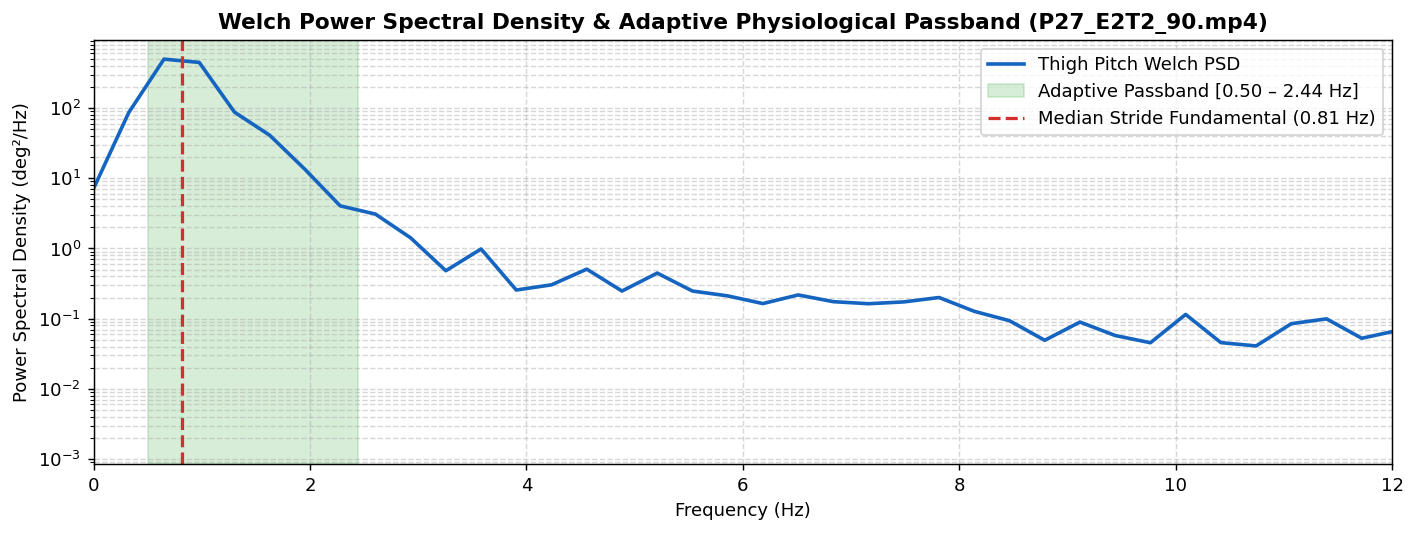

In [4]:
# Profile a representative batch of 20 IMU recordings to estimate adaptive cutoffs
csv_samples = [project_root / p for p in scanner.get_csvs()[:20]]
lowcut, highcut = estimator.estimate(csv_samples)
f_median = highcut / 3.0

# Compute Welch PSD on the current trial's unwrapped Pitch signal
df_unwrapped = estimator._unwrap_angles(df_raw.copy())
pitch_zero_mean = df_unwrapped["Pitch"].values - np.mean(df_unwrapped["Pitch"].values)
freqs, psd = sp_signal.welch(pitch_zero_mean, fs=fs, nperseg=min(256, len(pitch_zero_mean)))

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.semilogy(freqs, psd, color="#1565C0", lw=2.0, label="Thigh Pitch Welch PSD")
ax.axvspan(lowcut, highcut, color="#4CAF50", alpha=0.22, label=f"Adaptive Passband [{lowcut:.2f} – {highcut:.2f} Hz]")
ax.axvline(f_median, color="#D32F2F", ls="--", lw=1.8, label=f"Median Stride Fundamental ({f_median:.2f} Hz)")
ax.set_xlim(0, 12)
ax.set_title(f"Welch Power Spectral Density & Adaptive Physiological Passband ({video_info.name})", fontsize=12, fontweight="bold")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power Spectral Density (deg²/Hz)")
ax.legend(loc="upper right")
ax.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Dataset Median-Based Cutoffs -> Lowcut: {lowcut:.3f} Hz | Highcut: {highcut:.3f} Hz")

## 4. Zero-Phase Butterworth Bandpass Filtering (All 6 Channels)

We apply a 4th-order **Butterworth bandpass filter** using forward-backward filtering (`scipy.signal.filtfilt`) to all 6 kinematic channels (`accX, Pitch, accY, Roll, accZ, Yaw`). Prior to filtering, Euler angles are unwrapped (`np.unwrap`) to prevent $\pm 180^\circ$ phase-jump ringing. Because `filtfilt` has **zero phase distortion**, temporal alignment with video frames is strictly preserved.

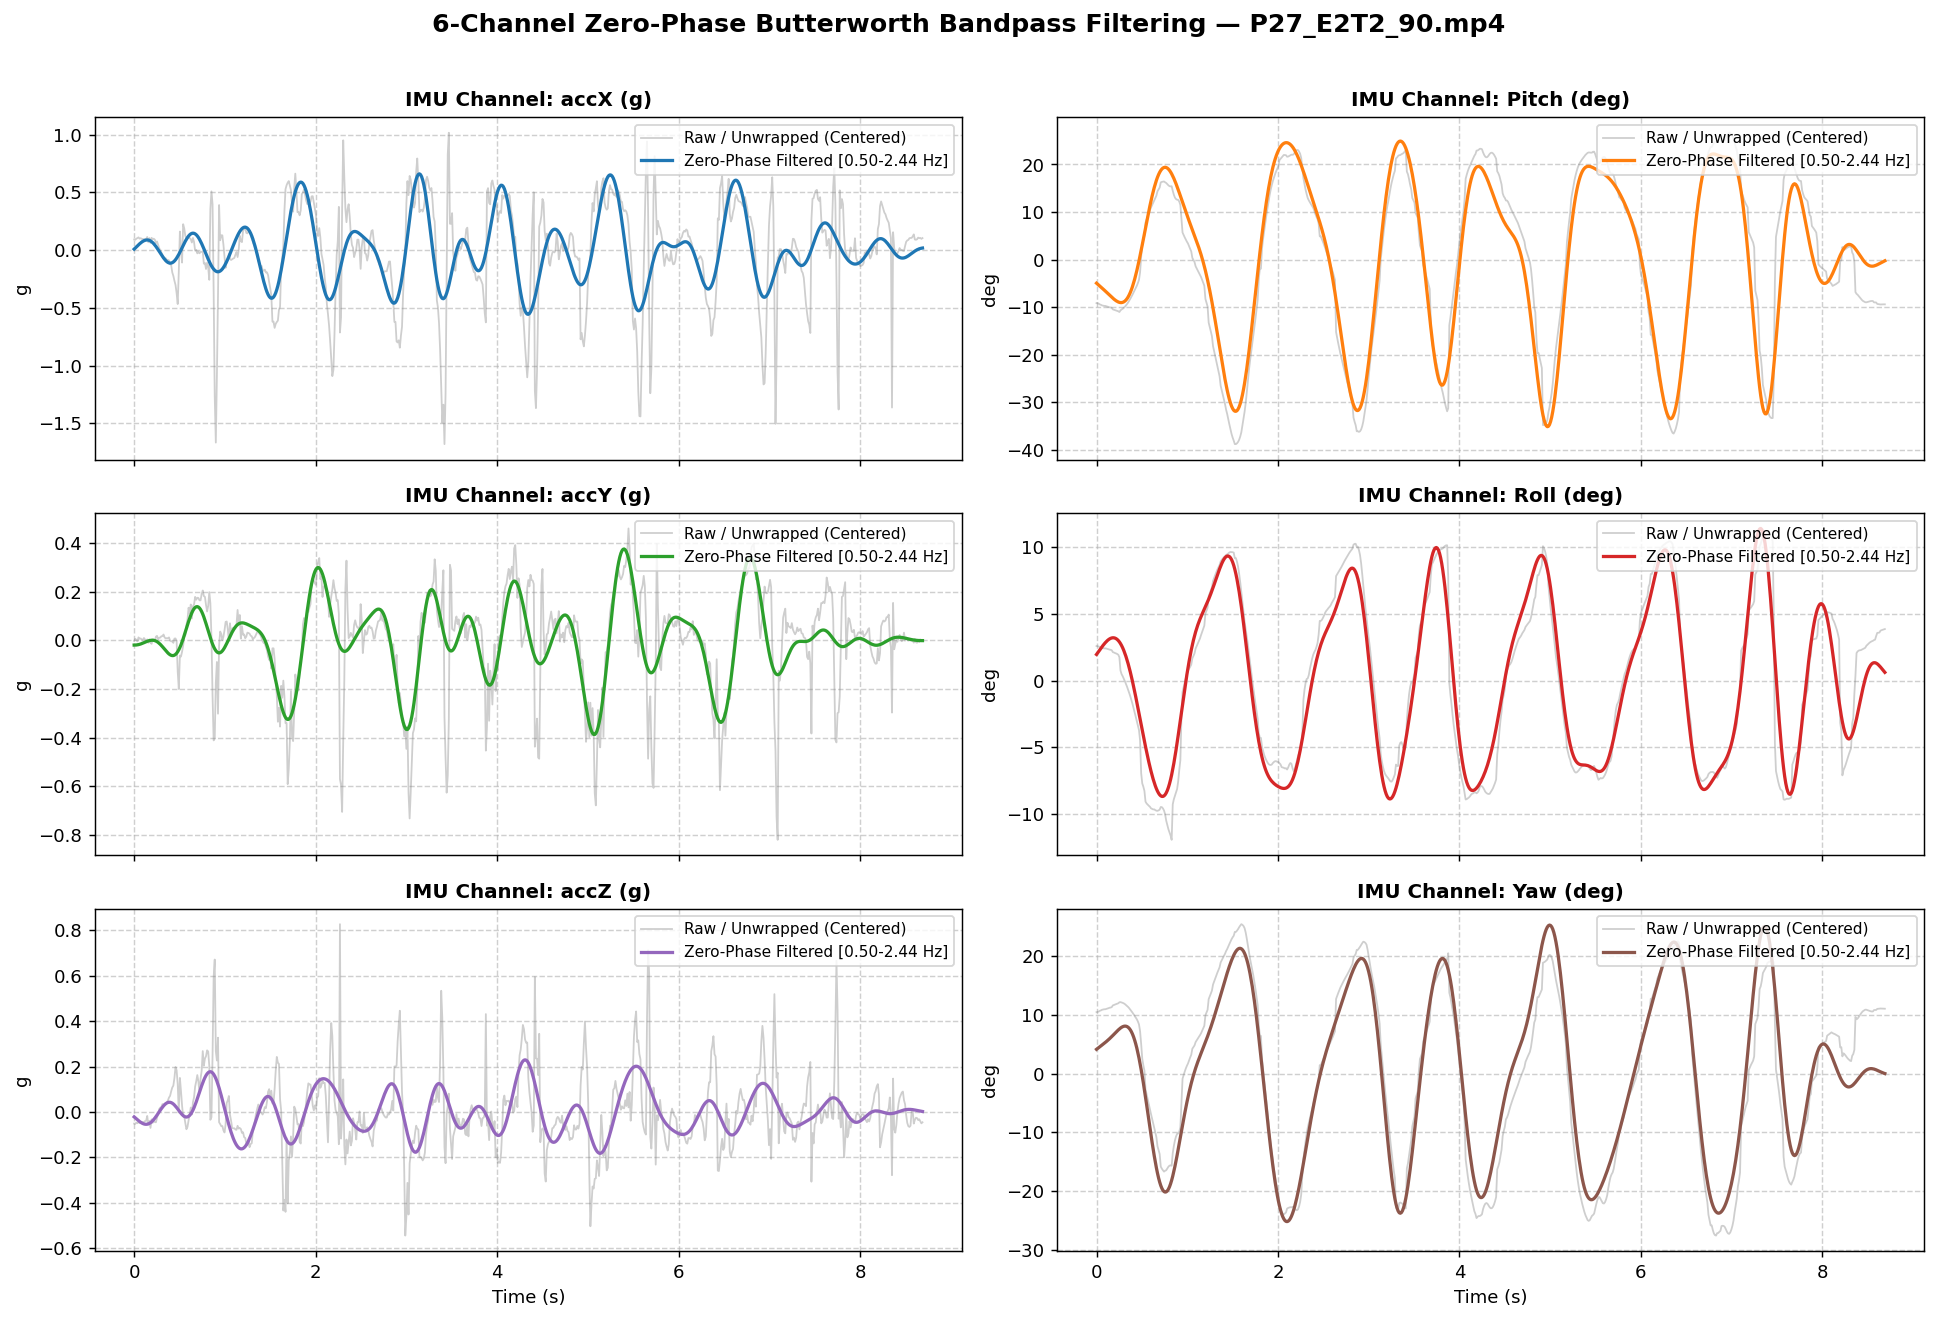

In [5]:
from src.preprocessing.signals.filtering import ButterworthSignalProcessor

processor = ButterworthSignalProcessor(order=4)
df_filtered = processor.process(df_unwrapped, lowcut, highcut)

fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
axes = axes.flatten()
signals_list = ["accX", "Pitch", "accY", "Roll", "accZ", "Yaw"]
units = ["g", "deg", "g", "deg", "g", "deg"]
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]

for i, (sig, unit, col) in enumerate(zip(signals_list, units, colors)):
    raw_centered = df_unwrapped[sig].values - np.mean(df_unwrapped[sig].values)
    axes[i].plot(df_raw["Timestamp"], raw_centered, color="gray", alpha=0.38, lw=1.0, label="Raw / Unwrapped (Centered)")
    axes[i].plot(df_filtered["Timestamp"], df_filtered[sig], color=col, lw=1.8, label=f"Zero-Phase Filtered [{lowcut:.2f}-{highcut:.2f} Hz]")
    axes[i].set_title(f"IMU Channel: {sig} ({unit})", fontsize=11, fontweight="bold")
    axes[i].set_ylabel(unit)
    axes[i].legend(loc="upper right", fontsize=8.5)
    axes[i].grid(True, linestyle="--", alpha=0.6)

axes[4].set_xlabel("Time (s)")
axes[5].set_xlabel("Time (s)")
fig.suptitle(f"6-Channel Zero-Phase Butterworth Bandpass Filtering — {video_info.name}", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 5. 3D Phase-Space Trajectory Visualization

Visualizing the 3D state-space orbits of the acceleration vector $[\text{accX}, \text{accY}, \text{accZ}]$ and orientation vector $[\text{Roll}, \text{Pitch}, \text{Yaw}]$ highlights how zero-phase bandpass filtering suppresses stochastic sensor noise while preserving the smooth, periodic attractor of bipedal locomotion.

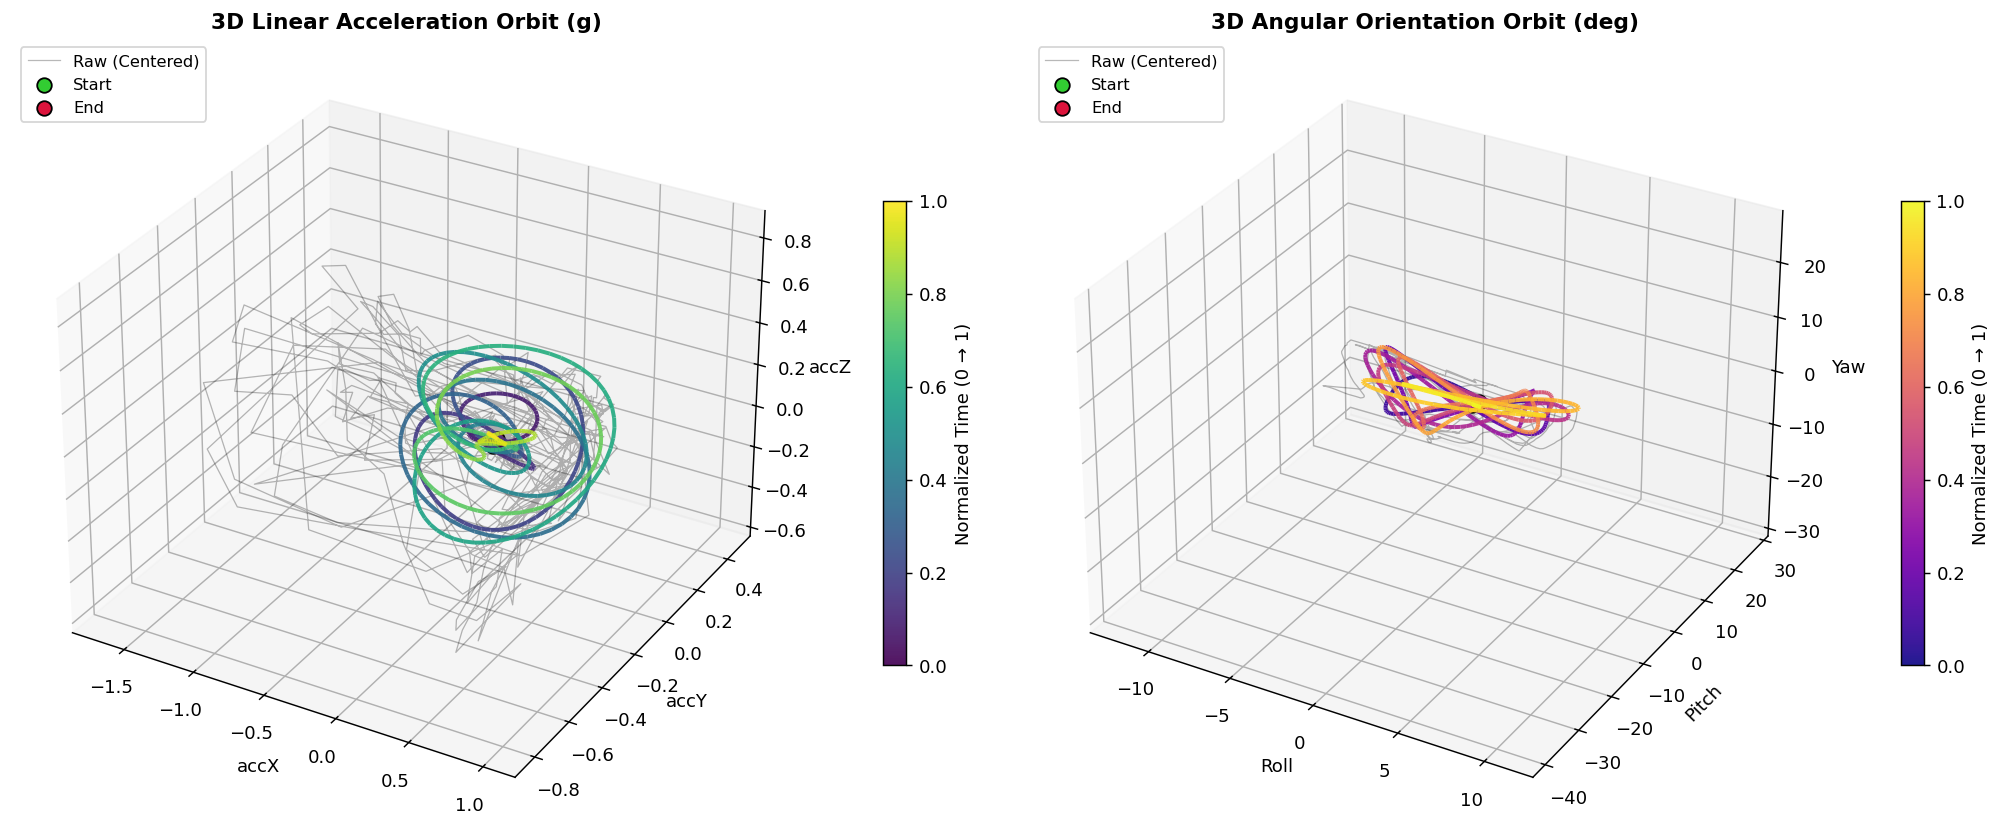

In [6]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection

def plot_3d_trajectory(ax, df_r, df_f, cols, title, cmap="viridis"):
    xr = df_r[cols[0]].values - np.mean(df_r[cols[0]].values)
    yr = df_r[cols[1]].values - np.mean(df_r[cols[1]].values)
    zr = df_r[cols[2]].values - np.mean(df_r[cols[2]].values)

    xf, yf, zf = df_f[cols[0]].values, df_f[cols[1]].values, df_f[cols[2]].values

    ax.plot(xr, yr, zr, color="black", alpha=0.28, lw=0.7, label="Raw (Centered)")

    pts = np.array([xf, yf, zf]).T.reshape(-1, 1, 3)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc = Line3DCollection(segs, cmap=cmap, norm=plt.Normalize(0, 1), lw=2.2, alpha=0.92)
    lc.set_array(np.linspace(0, 1, len(segs)))
    ax.add_collection(lc)

    ax.scatter(xf[0], yf[0], zf[0], color="limegreen", s=65, edgecolors="black", label="Start", zorder=10)
    ax.scatter(xf[-1], yf[-1], zf[-1], color="crimson", s=65, edgecolors="black", label="End", zorder=10)

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(cols[0])
    ax.set_ylabel(cols[1])
    ax.set_zlabel(cols[2])
    ax.legend(loc="upper left", fontsize=9)
    return lc

fig = plt.figure(figsize=(16, 6.8))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
lc1 = plot_3d_trajectory(ax1, df_unwrapped, df_filtered, ["accX", "accY", "accZ"], "3D Linear Acceleration Orbit (g)", cmap="viridis")
fig.colorbar(lc1, ax=ax1, shrink=0.55, pad=0.08, label="Normalized Time (0 → 1)")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
lc2 = plot_3d_trajectory(ax2, df_unwrapped, df_filtered, ["Roll", "Pitch", "Yaw"], "3D Angular Orientation Orbit (deg)", cmap="plasma")
fig.colorbar(lc2, ax=ax2, shrink=0.55, pad=0.08, label="Normalized Time (0 → 1)")

plt.tight_layout()
plt.show()

## 6. Physiological Signal Quality Validation

Finally, `PhysiologicalSignalValidator` verifies that the filtered IMU signal meets biomechanical integrity criteria (sufficient stride Range of Motion, absence of NaN/flatline dropouts, and physiological variance) before admitting the trial into the 3D tracking benchmark.

In [7]:
from src.preprocessing.signals.validation import PhysiologicalSignalValidator

validator = PhysiologicalSignalValidator()
is_valid = validator.is_valid(df_filtered)
pitch_rom = float(np.ptp(df_filtered["Pitch"].values))

print(f"Physiological Validity Check : {'PASS' if is_valid else 'REJECTED'}")
print(f"Filtered Thigh Pitch ROM     : {pitch_rom:.2f}°")

Physiological Validity Check : PASS
Filtered Thigh Pitch ROM     : 60.07°
